# 🏥 MediTOD NER — Medical Dialogue Entity Recognition

**Task:** 12-class Token Classification (25 BIO labels) on Indian English Clinical Dialogues  
**Model:** PubMedBERT with Focal Loss + Context Windows  
**Dataset:** 204 dialogues (164 train / 20 val / 20 test)

---
## Cell 1 — Install Dependencies

In [11]:
# Upgrade Python packaging tools
!python -m pip install -q --upgrade pip setuptools wheel

In [12]:
# Install Hugging Face packages
!python -m pip install -q \
    "transformers==4.57.3" \
    "tokenizers==0.22.1" \
    datasets \
    accelerate

In [13]:
# Scientific / ML packages
!python -m pip install -q \
    scikit-learn \
    matplotlib

In [14]:
!python -m pip install -q --no-cache-dir --use-pep517 seqeval

In [15]:
import transformers
import tokenizers

print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)

Transformers: 4.57.3
Tokenizers: 0.22.1


---
## Cell 2 — Imports & Configuration

In [16]:
import json
import os
import random
import time
import warnings
from collections import Counter, defaultdict
from datetime import datetime

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from seqeval.metrics import classification_report as seq_classification_report
from seqeval.metrics import f1_score as seq_f1_score
from seqeval.scheme import IOB2
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# ── Reproducibility ──
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ── Device ──
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Using device: cuda
GPU: Tesla T4
VRAM: 15.6 GB


---
## Cell 3 — Hyperparameters & Label Schema

In [17]:
# ══════════════════════════════════════════════════════════════
#  HYPERPARAMETERS
# ══════════════════════════════════════════════════════════════
MODEL_NAME        = 'microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext'
MAX_SEQ_LEN       = 256
CONTEXT_WINDOW    = 2          # Number of preceding turns as context
BATCH_SIZE        = 16
GRAD_ACCUM_STEPS  = 2          # Effective batch size = 32
LEARNING_RATE     = 3e-5
WEIGHT_DECAY      = 0.01
NUM_EPOCHS        = 15
WARMUP_RATIO      = 0.10
PATIENCE          = 5          # Early stopping patience
FREEZE_LAYERS     = 6          # Freeze bottom N transformer layers
FOCAL_GAMMA       = 1.2        # v2: reduced from 1.8 to curb over-tagging
LABEL_SMOOTHING   = 0.0        # v2: removed — NER needs crisp O/B/I boundaries
O_TAG_WEIGHT      = 0.40       # v2: raised from 0.20 to penalise false positives harder
ALL_O_KEEP_RATIO  = 0.40       # v2: raised from 0.25 — model needs more negative examples

# ── BIO Label Schema (12 entity types × 2 + O = 25 labels) ──

LABEL_LIST = [
    'O',
    'B-SYMPTOM_VALUE',         'I-SYMPTOM_VALUE',
    'B-SYMPTOM_LOCATION',      'I-SYMPTOM_LOCATION',
    'B-SYMPTOM_CHARACTERISTICS','I-SYMPTOM_CHARACTERISTICS',
    'B-SYMPTOM_FREQUENCY',     'I-SYMPTOM_FREQUENCY',
    'B-TEMPORAL',              'I-TEMPORAL',
    'B-MEDICATION',            'I-MEDICATION',
    'B-MEDICAL_TEST_NAME',     'I-MEDICAL_TEST_NAME',
    'B-MEDICAL_HISTORY_VALUE', 'I-MEDICAL_HISTORY_VALUE',
    'B-HABIT_VALUE',           'I-HABIT_VALUE',
    'B-HABIT_FREQUENCY',       'I-HABIT_FREQUENCY',
    'B-EXPOSURE_VALUE',        'I-EXPOSURE_VALUE',
    'B-POLARITY',              'I-POLARITY',
]

label2id = {l: i for i, l in enumerate(LABEL_LIST)}
id2label = {i: l for i, l in enumerate(LABEL_LIST)}
NUM_LABELS = len(LABEL_LIST)

print(f'Model:       {MODEL_NAME}')
print(f'Labels:      {NUM_LABELS} ({NUM_LABELS // 2} entity types + O)')
print(f'Max seq len: {MAX_SEQ_LEN}')
print(f'Context:     {CONTEXT_WINDOW} preceding turns')
print(f'Batch:       {BATCH_SIZE} × {GRAD_ACCUM_STEPS} = {BATCH_SIZE * GRAD_ACCUM_STEPS} effective')

Model:       microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext
Labels:      25 (12 entity types + O)
Max seq len: 256
Context:     2 preceding turns
Batch:       16 × 2 = 32 effective


---
## Cell 4 — Load Dataset & Build Context Windows

In [18]:
# ══════════════════════════════════════════════════════════════
#  DATA LOADING
# ══════════════════════════════════════════════════════════════
# Update these paths to your Kaggle dataset paths
DATA_DIR = '/kaggle/input/datasets/ammuaman18/fyp-claude'   # << Change this to your Kaggle dataset slug

def load_jsonl(path):
    data = []
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data.append(json.loads(line))
    return data

train_dialogues = load_jsonl(os.path.join(DATA_DIR, 'train.jsonl'))
val_dialogues   = load_jsonl(os.path.join(DATA_DIR, 'val.jsonl'))
test_dialogues  = load_jsonl(os.path.join(DATA_DIR, 'test.jsonl'))

print(f'Train: {len(train_dialogues)} dialogues')
print(f'Val:   {len(val_dialogues)} dialogues')
print(f'Test:  {len(test_dialogues)} dialogues')

# ══════════════════════════════════════════════════════════════
#  CONTEXT WINDOW BUILDER
# ══════════════════════════════════════════════════════════════
def build_examples(dialogues, is_train=False):
    """Build training examples with context windows.
    
    For each target utterance U_i, construct:
      tokens  = [SPK] U_{i-2} [SEP] [SPK] U_{i-1} [SEP] [SPK] U_i
      labels  = [-100 ...context...] [-100 ...context...] [actual BIO labels]
    """
    examples = []
    skipped_all_o = 0
    
    for dialogue in dialogues:
        turns = dialogue['utterances']
        
        for target_idx in range(len(turns)):
            target = turns[target_idx]
            target_tags = target['ner_tags']
            
            # ALL_O_KEEP_RATIO subsampling (training only)
            if is_train:
                has_entity = any(t != 'O' for t in target_tags)
                if not has_entity and random.random() > ALL_O_KEEP_RATIO:
                    skipped_all_o += 1
                    continue
            
            # Build context
            context_tokens = []
            context_labels = []
            start = max(0, target_idx - CONTEXT_WINDOW)
            
            for i in range(start, target_idx):
                ctx_turn = turns[i]
                spk = f"{ctx_turn['speaker']}:"
                toks = [spk] + ctx_turn['tokens']
                context_tokens.extend(toks)
                context_labels.extend([-100] * len(toks))
            
            # Build target
            spk = f"{target['speaker']}:"
            target_tokens = [spk] + target['tokens']
            target_label_ids = [-100] + [label2id.get(t, 0) for t in target_tags]
            
            all_tokens = context_tokens + target_tokens
            all_labels = context_labels + target_label_ids
            
            examples.append({
                'tokens': all_tokens,
                'labels': all_labels,
                'dialogue_id': dialogue.get('id', '?'),
                'turn_idx': target_idx,
            })
    
    if is_train:
        print(f'  Skipped {skipped_all_o} all-O utterances (ALL_O_KEEP_RATIO={ALL_O_KEEP_RATIO})')
    return examples

print('\nBuilding context windows...')
train_examples = build_examples(train_dialogues, is_train=True)
val_examples   = build_examples(val_dialogues,   is_train=False)
test_examples  = build_examples(test_dialogues,  is_train=False)

print(f'\nTrain examples: {len(train_examples)}')
print(f'Val examples:   {len(val_examples)}')
print(f'Test examples:  {len(test_examples)}')

Train: 164 dialogues
Val:   20 dialogues
Test:  20 dialogues

Building context windows...
  Skipped 258 all-O utterances (ALL_O_KEEP_RATIO=0.4)

Train examples: 3822
Val examples:   493
Test examples:  497


---
## Cell 5 — Tokenization & Label Alignment

In [19]:
# ══════════════════════════════════════════════════════════════
#  TOKENIZER & SUBWORD ALIGNMENT
# ══════════════════════════════════════════════════════════════
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class NERDataset(Dataset):
    def __init__(self, examples, tokenizer, max_len=MAX_SEQ_LEN):
        self.examples = examples
        self.tokenizer = tokenizer
        self.max_len = max_len
    
    def __len__(self):
        return len(self.examples)
    
    def __getitem__(self, idx):
        ex = self.examples[idx]
        tokens = ex['tokens']
        labels = ex['labels']
        
        # Tokenize with is_split_into_words=True
        encoding = self.tokenizer(
            tokens,
            is_split_into_words=True,
            truncation=True,
            max_length=self.max_len,
            padding='max_length',
            return_tensors='pt',
        )
        
        # Align labels to subword tokens
        word_ids = encoding.word_ids()
        aligned_labels = []
        prev_word_id = None
        
        for word_id in word_ids:
            if word_id is None:
                aligned_labels.append(-100)  # [CLS], [SEP], [PAD]
            elif word_id >= len(labels):
                aligned_labels.append(-100)  # Truncated
            elif word_id != prev_word_id:
                aligned_labels.append(labels[word_id])  # First subword
            else:
                # Continuation subword: inherit label
                lbl = labels[word_id]
                if lbl != -100 and id2label.get(lbl, 'O').startswith('B-'):
                    # B- → I- for continuation subwords
                    i_tag = 'I-' + id2label[lbl][2:]
                    aligned_labels.append(label2id.get(i_tag, lbl))
                else:
                    aligned_labels.append(lbl)
            prev_word_id = word_id
        
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(aligned_labels, dtype=torch.long),
        }

train_dataset = NERDataset(train_examples, tokenizer)
val_dataset   = NERDataset(val_examples, tokenizer)
test_dataset  = NERDataset(test_examples, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Quick sanity check
batch = next(iter(train_loader))
print(f'input_ids shape:      {batch["input_ids"].shape}')
print(f'attention_mask shape: {batch["attention_mask"].shape}')
print(f'labels shape:         {batch["labels"].shape}')
print(f'Non -100 labels in batch: {(batch["labels"] != -100).sum().item()}')

input_ids shape:      torch.Size([16, 256])
attention_mask shape: torch.Size([16, 256])
labels shape:         torch.Size([16, 256])
Non -100 labels in batch: 528


---
## Cell 6 — Model, Loss Function & Optimizer

In [20]:
# ══════════════════════════════════════════════════════════════
#  FOCAL LOSS
# ══════════════════════════════════════════════════════════════
class FocalLoss(nn.Module):
    def __init__(self, gamma=1.8, alpha=None, label_smoothing=0.03):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing
        self.alpha = alpha
    
    def forward(self, logits, targets):
        num_classes = logits.size(-1)
        ce_loss = F.cross_entropy(
            logits.view(-1, num_classes),
            targets.view(-1),
            weight=self.alpha,
            label_smoothing=self.label_smoothing,
            reduction='none',
            ignore_index=-100,
        )
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

# ══════════════════════════════════════════════════════════════
#  MODEL SETUP
# ══════════════════════════════════════════════════════════════
class MediTODNER(nn.Module):
    def __init__(self, model_name, num_labels, dropout=0.1):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)
    
    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        logits = self.classifier(self.dropout(outputs.last_hidden_state))
        return logits

model = MediTODNER(MODEL_NAME, NUM_LABELS).to(device)

# ── Freeze bottom layers ──
frozen_params = 0
for name, param in model.named_parameters():
    if 'embeddings' in name:
        param.requires_grad = False
        frozen_params += param.numel()
    elif 'encoder.layer' in name:
        layer_num = int(name.split('encoder.layer.')[1].split('.')[0])
        if layer_num < FREEZE_LAYERS:
            param.requires_grad = False
            frozen_params += param.numel()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_p = sum(p.numel() for p in model.parameters())
print(f'\n═══ Model Architecture ═══')
print(f'Total params:     {total_p:>12,}')
print(f'Frozen params:    {frozen_params:>12,}')
print(f'Trainable params: {trainable:>12,} ({100*trainable/total_p:.1f}%)')
print(f'Frozen layers:    0-{FREEZE_LAYERS-1} + embeddings')

# ── Loss ──
class_weights = torch.ones(NUM_LABELS, device=device)
class_weights[label2id['O']] = O_TAG_WEIGHT
criterion = FocalLoss(gamma=FOCAL_GAMMA, alpha=class_weights, label_smoothing=LABEL_SMOOTHING)

# ── Optimizer ──
optimizer = AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

total_steps = (len(train_loader) // GRAD_ACCUM_STEPS) * NUM_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

print(f'\n═══ Training Config ═══')
print(f'Total steps:  {total_steps}')
print(f'Warmup steps: {warmup_steps}')
print(f'Loss:         FocalLoss(γ={FOCAL_GAMMA}, smoothing={LABEL_SMOOTHING})')
print(f'O-tag weight: {O_TAG_WEIGHT}')

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]


═══ Model Architecture ═══
Total params:      109,501,465
Frozen params:      66,364,416
Trainable params:   43,137,049 (39.4%)
Frozen layers:    0-5 + embeddings

═══ Training Config ═══
Total steps:  1785
Warmup steps: 178
Loss:         FocalLoss(γ=1.2, smoothing=0.0)
O-tag weight: 0.4


---
## Cell 7 — Training Loop with Detailed Logging

In [21]:
# ══════════════════════════════════════════════════════════════
#  EVALUATION HELPER
# ══════════════════════════════════════════════════════════════
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)
            total_loss += loss.item()
            
            preds = torch.argmax(logits, dim=-1)
            
            for pred_seq, label_seq in zip(preds, labels):
                pred_tags = []
                true_tags = []
                for p, l in zip(pred_seq.tolist(), label_seq.tolist()):
                    if l != -100:
                        pred_tags.append(id2label[p])
                        true_tags.append(id2label[l])
                if pred_tags:
                    all_preds.append(pred_tags)
                    all_labels.append(true_tags)
    
    avg_loss = total_loss / len(loader)
    entity_f1 = seq_f1_score(all_labels, all_preds, scheme=IOB2)
    
    return avg_loss, entity_f1, all_preds, all_labels

# ══════════════════════════════════════════════════════════════
#  TRAINING LOOP
# ══════════════════════════════════════════════════════════════
best_val_f1 = 0.0
best_epoch = 0
patience_counter = 0
history = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'lr': []}

print('═' * 90)
print(f'{"Epoch":>6} │ {"Train Loss":>11} │ {"Val Loss":>9} │ {"Val F1":>8} │ {"Best F1":>8} │ {"LR":>10} │ {"Time":>6} │ Status')
print('─' * 90)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()
    model.train()
    total_train_loss = 0
    num_batches = 0
    optimizer.zero_grad()
    
    for step, batch in enumerate(train_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss = loss / GRAD_ACCUM_STEPS
        loss.backward()
        
        total_train_loss += loss.item() * GRAD_ACCUM_STEPS
        num_batches += 1
        
        if (step + 1) % GRAD_ACCUM_STEPS == 0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
        
        # Progress logging every 50 batches
        if (step + 1) % 50 == 0:
            print(f'  [Epoch {epoch}] Step {step+1}/{len(train_loader)} | '
                  f'Batch Loss: {loss.item() * GRAD_ACCUM_STEPS:.4f} | '
                  f'LR: {scheduler.get_last_lr()[0]:.2e}')
    
    avg_train_loss = total_train_loss / num_batches
    current_lr = scheduler.get_last_lr()[0]
    
    # Validation
    val_loss, val_f1, _, _ = evaluate(model, val_loader, criterion)
    
    epoch_time = time.time() - epoch_start
    
    # Track history
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(val_loss)
    history['val_f1'].append(val_f1)
    history['lr'].append(current_lr)
    
    # Early stopping check
    status = ''
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0
        status = '⭐ NEW BEST'
        # Save best checkpoint
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_loss': val_loss,
        }, 'best_model.pt')
    else:
        patience_counter += 1
        status = f'patience {patience_counter}/{PATIENCE}'
    
    print(f'{epoch:>6} │ {avg_train_loss:>11.4f} │ {val_loss:>9.4f} │ {val_f1:>8.4f} │ {best_val_f1:>8.4f} │ {current_lr:>10.2e} │ {epoch_time:>5.1f}s │ {status}')
    
    if patience_counter >= PATIENCE:
        print(f'\n🛑 Early stopping triggered at epoch {epoch}. Best epoch: {best_epoch} (F1={best_val_f1:.4f})')
        break

print('─' * 90)
print(f'\n✅ Training complete. Best Val F1: {best_val_f1:.4f} at epoch {best_epoch}')

══════════════════════════════════════════════════════════════════════════════════════════
 Epoch │  Train Loss │  Val Loss │   Val F1 │  Best F1 │         LR │   Time │ Status
──────────────────────────────────────────────────────────────────────────────────────────
  [Epoch 1] Step 50/239 | Batch Loss: 0.1550 | LR: 4.21e-06
  [Epoch 1] Step 100/239 | Batch Loss: 0.0696 | LR: 8.43e-06
  [Epoch 1] Step 150/239 | Batch Loss: 0.0738 | LR: 1.26e-05
  [Epoch 1] Step 200/239 | Batch Loss: 0.0384 | LR: 1.69e-05
     1 │      0.0978 │    0.0305 │   0.5191 │   0.5191 │   2.01e-05 │ 106.1s │ ⭐ NEW BEST
  [Epoch 2] Step 50/239 | Batch Loss: 0.0188 | LR: 2.43e-05
  [Epoch 2] Step 100/239 | Batch Loss: 0.0181 | LR: 2.85e-05
  [Epoch 2] Step 150/239 | Batch Loss: 0.0096 | LR: 2.97e-05
  [Epoch 2] Step 200/239 | Batch Loss: 0.0132 | LR: 2.92e-05
     2 │      0.0201 │    0.0096 │   0.6373 │   0.6373 │   2.89e-05 │ 115.7s │ ⭐ NEW BEST
  [Epoch 3] Step 50/239 | Batch Loss: 0.0120 | LR: 2.84e-05
  [Epo

---
## Cell 8 — Training Curves

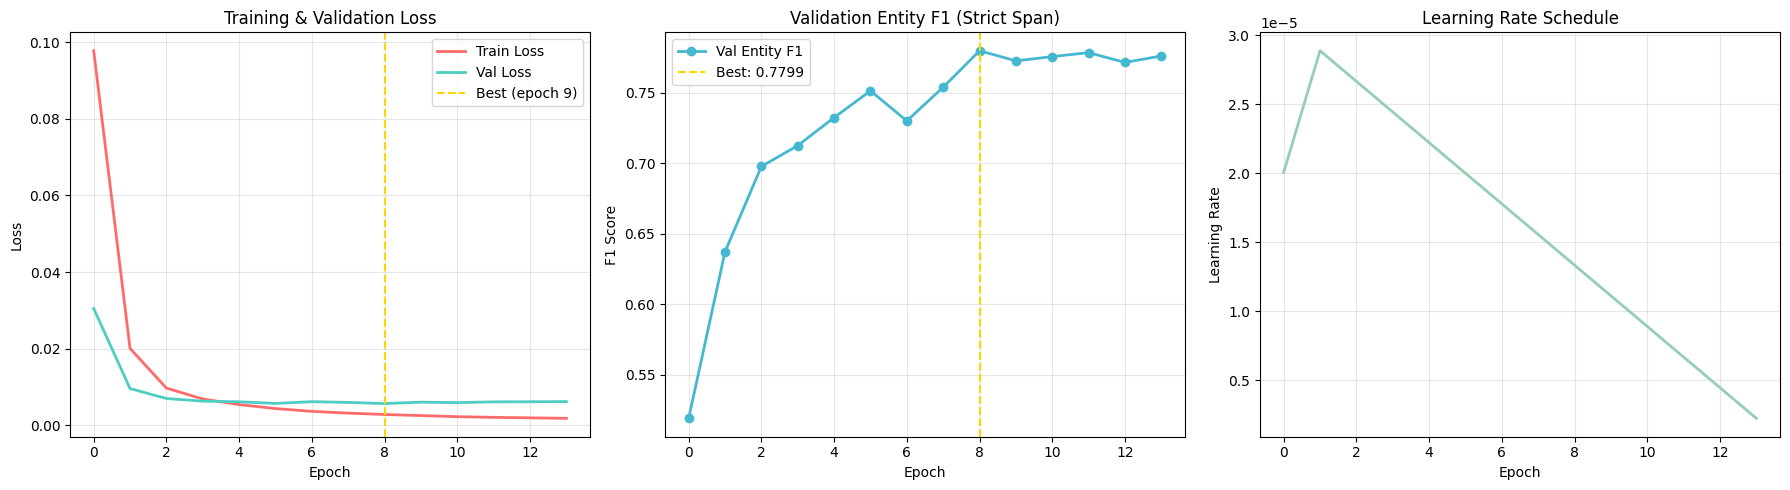

Saved training_curves.png


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss curves
axes[0].plot(history['train_loss'], label='Train Loss', color='#FF6B6B', linewidth=2)
axes[0].plot(history['val_loss'], label='Val Loss', color='#4ECDC4', linewidth=2)
axes[0].axvline(x=best_epoch-1, color='gold', linestyle='--', label=f'Best (epoch {best_epoch})')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# F1 curve
axes[1].plot(history['val_f1'], label='Val Entity F1', color='#45B7D1', linewidth=2, marker='o')
axes[1].axvline(x=best_epoch-1, color='gold', linestyle='--', label=f'Best: {best_val_f1:.4f}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('F1 Score')
axes[1].set_title('Validation Entity F1 (Strict Span)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# LR schedule
axes[2].plot(history['lr'], color='#96CEB4', linewidth=2)
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')
axes[2].set_title('Learning Rate Schedule')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved training_curves.png')

---
## Cell 9 — Evaluation on Test Set

In [23]:
# ══════════════════════════════════════════════════════════════
#  LOAD BEST CHECKPOINT & EVALUATE ON TEST SET
# ══════════════════════════════════════════════════════════════
checkpoint = torch.load('best_model.pt', map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
print(f'Loaded best model from epoch {checkpoint["epoch"]} (Val F1: {checkpoint["val_f1"]:.4f})')

test_loss, test_f1, test_preds, test_labels = evaluate(model, test_loader, criterion)

print(f'\n{"═" * 70}')
print(f'  TEST SET RESULTS')
print(f'{"═" * 70}')
print(f'  Test Loss:      {test_loss:.4f}')
print(f'  Test Entity F1: {test_f1:.4f}')
print(f'{"═" * 70}')

# ── Per-entity classification report ──
print('\n── Per-Entity Classification Report (seqeval strict span) ──\n')
report = seq_classification_report(test_labels, test_preds, scheme=IOB2, digits=4)
print(report)

Loaded best model from epoch 9 (Val F1: 0.7799)

══════════════════════════════════════════════════════════════════════
  TEST SET RESULTS
══════════════════════════════════════════════════════════════════════
  Test Loss:      0.0067
  Test Entity F1: 0.7944
══════════════════════════════════════════════════════════════════════

── Per-Entity Classification Report (seqeval strict span) ──

                         precision    recall  f1-score   support

         EXPOSURE_VALUE     0.7692    0.9474    0.8491        95
        HABIT_FREQUENCY     0.5902    0.8372    0.6923        43
            HABIT_VALUE     0.7134    0.8931    0.7932       131
  MEDICAL_HISTORY_VALUE     0.7890    0.7544    0.7713       114
      MEDICAL_TEST_NAME     0.8052    0.8794    0.8407       141
             MEDICATION     0.8743    0.9182    0.8957       159
               POLARITY     0.3481    0.8462    0.4933        65
SYMPTOM_CHARACTERISTICS     0.4086    0.6129    0.4903        62
      SYMPTOM_FREQUE

---
## Cell 10 — Confusion Matrix

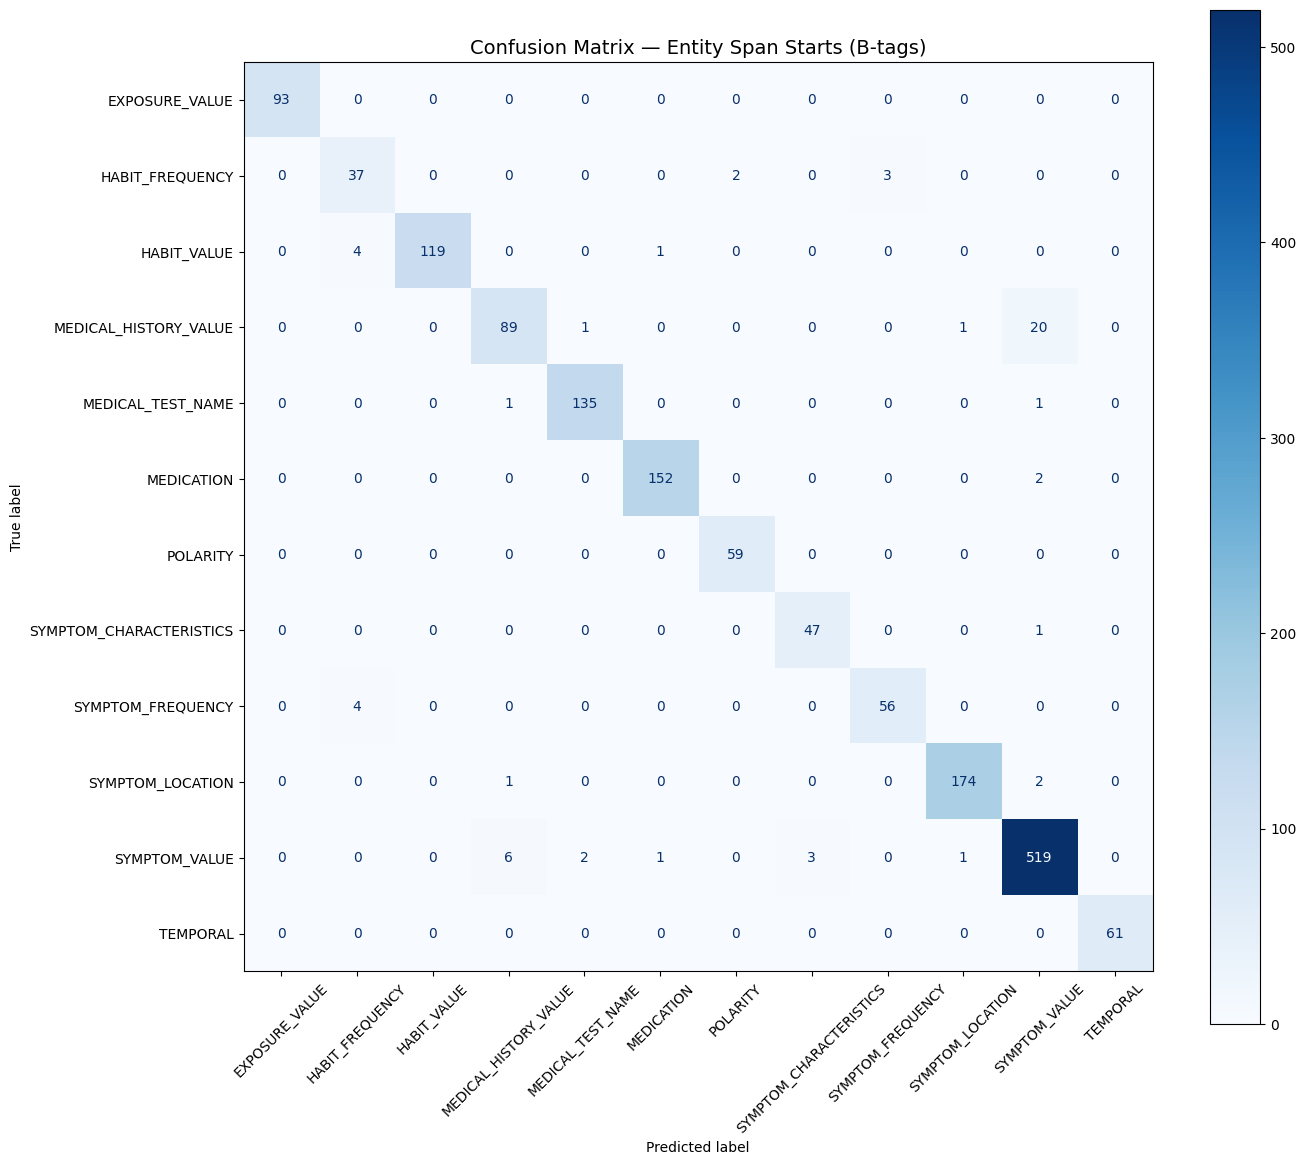

Saved confusion_matrix.png

── Token-Level Accuracy Breakdown ──
  Overall accuracy:  15635/16498 (94.77%)
  O-tag accuracy:    12865/13441 (95.71%)
  Entity accuracy:   2770/3057 (90.61%)


In [24]:
# ══════════════════════════════════════════════════════════════
#  CONFUSION MATRIX (entity-level, excluding O)
# ══════════════════════════════════════════════════════════════
# Flatten predictions and labels
flat_preds = [t for seq in test_preds for t in seq]
flat_labels = [t for seq in test_labels for t in seq]

# Get unique entity labels (excluding O)
entity_labels = sorted(set(flat_preds + flat_labels) - {'O'})

# Include O for completeness
all_display_labels = ['O'] + entity_labels

cm = confusion_matrix(flat_labels, flat_preds, labels=all_display_labels)

# Plot a compact version with just entity B-tags
b_labels = sorted([l for l in set(flat_preds + flat_labels) if l.startswith('B-')])
b_short = [l.replace('B-', '') for l in b_labels]

# Filter to only B-tag predictions
b_preds  = [t if t.startswith('B-') else 'OTHER' for t in flat_preds]
b_truths = [t if t.startswith('B-') else 'OTHER' for t in flat_labels]

fig, ax = plt.subplots(figsize=(14, 12))
cm_b = confusion_matrix(b_truths, b_preds, labels=b_labels)
disp = ConfusionMatrixDisplay(cm_b, display_labels=b_short)
disp.plot(ax=ax, cmap='Blues', values_format='d', xticks_rotation=45)
ax.set_title('Confusion Matrix — Entity Span Starts (B-tags)', fontsize=14)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved confusion_matrix.png')

# ── Token-level accuracy breakdown ──
print('\n── Token-Level Accuracy Breakdown ──')
correct = sum(1 for p, l in zip(flat_preds, flat_labels) if p == l)
total_tok = len(flat_preds)
o_correct = sum(1 for p, l in zip(flat_preds, flat_labels) if p == l and l == 'O')
o_total = sum(1 for l in flat_labels if l == 'O')
ent_correct = correct - o_correct
ent_total = total_tok - o_total

print(f'  Overall accuracy:  {correct}/{total_tok} ({100*correct/total_tok:.2f}%)')
print(f'  O-tag accuracy:    {o_correct}/{o_total} ({100*o_correct/o_total:.2f}%)')
print(f'  Entity accuracy:   {ent_correct}/{ent_total} ({100*ent_correct/max(ent_total,1):.2f}%)')

---
## Cell 11 — Inference Examples

In [25]:
# ══════════════════════════════════════════════════════════════
#  INFERENCE ON EXAMPLE SENTENCES
# ══════════════════════════════════════════════════════════════
# v2: Added confidence threshold to filter low-confidence entity predictions
MIN_CONFIDENCE = 0.40  # Only predict entity if softmax > this threshold

def predict_sentence(text, model, tokenizer, min_confidence=MIN_CONFIDENCE):
    """Run NER inference on a single sentence with confidence filtering."""
    model.eval()
    tokens = text.split()
    encoding = tokenizer(
        tokens,
        is_split_into_words=True,
        truncation=True,
        max_length=MAX_SEQ_LEN,
        return_tensors='pt',
    )
    
    with torch.no_grad():
        input_ids = encoding['input_ids'].to(device)
        attention_mask = encoding['attention_mask'].to(device)
        logits = model(input_ids, attention_mask)
        probs = torch.softmax(logits, dim=-1)[0]  # (seq_len, num_labels)
        preds = torch.argmax(probs, dim=-1)        # (seq_len,)
    
    word_ids = encoding.word_ids()
    results = []
    prev_word_id = None
    for i, word_id in enumerate(word_ids):
        if word_id is not None and word_id != prev_word_id:
            pred_id = preds[i].item()
            confidence = probs[i, pred_id].item()
            tag = id2label[pred_id]
            # v2: If entity prediction is below threshold, default to O
            if tag != 'O' and confidence < min_confidence:
                tag = 'O'
            results.append((tokens[word_id], tag))
        prev_word_id = word_id
    return results

# ── Test examples ──
examples = [
    'Doctor: I am prescribing you metformin 500mg twice daily for your diabetes',
    'Patient: I have been having severe headache and chest pain since last week',
    'Patient: Yes doctor I smoke about 10 cigarettes a day and drink occasionally',
    'Doctor: Your CBC report shows low hemoglobin and thyroid is normal',
    'Patient: No I stopped taking amlodipine three months ago because of side effects',
]

print('═' * 80)
print('  INFERENCE EXAMPLES')
print('═' * 80)

for text in examples:
    results = predict_sentence(text, model, tokenizer)
    print(f'\n📝 Input: {text}')
    print('   Entities found:')
    
    current_entity = []
    current_tag = None
    
    for token, tag in results:
        if tag.startswith('B-'):
            if current_entity:
                print(f'     [{current_tag}] {" ".join(current_entity)}')
            current_entity = [token]
            current_tag = tag[2:]
        elif tag.startswith('I-') and current_tag == tag[2:]:
            current_entity.append(token)
        else:
            if current_entity:
                print(f'     [{current_tag}] {" ".join(current_entity)}')
                current_entity = []
                current_tag = None
    if current_entity:
        print(f'     [{current_tag}] {" ".join(current_entity)}')
    
    print()

════════════════════════════════════════════════════════════════════════════════
  INFERENCE EXAMPLES
════════════════════════════════════════════════════════════════════════════════

📝 Input: Doctor: I am prescribing you metformin 500mg twice daily for your diabetes
   Entities found:
     [MEDICATION] metformin
     [SYMPTOM_FREQUENCY] twice


📝 Input: Patient: I have been having severe headache and chest pain since last week
   Entities found:
     [SYMPTOM_VALUE] severe
     [SYMPTOM_VALUE] headache
     [SYMPTOM_VALUE] chest pain
     [TEMPORAL] since last week


📝 Input: Patient: Yes doctor I smoke about 10 cigarettes a day and drink occasionally
   Entities found:
     [POLARITY] Yes
     [HABIT_VALUE] smoke
     [HABIT_FREQUENCY] 10 cigarettes a day
     [HABIT_VALUE] drink


📝 Input: Doctor: Your CBC report shows low hemoglobin and thyroid is normal
   Entities found:
     [MEDICAL_TEST_NAME] CBC report
     [SYMPTOM_VALUE] hemoglobin


📝 Input: Patient: No I stopped taking am

---
## Cell 12 — Save Best Weights & Reports

In [26]:
# ══════════════════════════════════════════════════════════════
#  SAVE EVERYTHING FOR DOWNLOAD
# ══════════════════════════════════════════════════════════════
import shutil

SAVE_DIR = '/kaggle/working/meditod_ner_output'
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Save model weights (best checkpoint)
model_save_dir = os.path.join(SAVE_DIR, 'model')
os.makedirs(model_save_dir, exist_ok=True)
shutil.copy('best_model.pt', os.path.join(model_save_dir, 'best_model.pt'))

# 2. Save tokenizer
tokenizer.save_pretrained(model_save_dir)

# 3. Save label map
with open(os.path.join(model_save_dir, 'label_map.json'), 'w') as f:
    json.dump({'label2id': label2id, 'id2label': id2label}, f, indent=2)

# 4. Save training config
config = {
    'model_name': MODEL_NAME,
    'max_seq_len': MAX_SEQ_LEN,
    'context_window': CONTEXT_WINDOW,
    'freeze_layers': FREEZE_LAYERS,
    'focal_gamma': FOCAL_GAMMA,
    'label_smoothing': LABEL_SMOOTHING,
    'o_tag_weight': O_TAG_WEIGHT,
    'all_o_keep_ratio': ALL_O_KEEP_RATIO,
    'min_confidence': 0.40,
    'learning_rate': LEARNING_RATE,
    'batch_size': BATCH_SIZE,
    'grad_accum_steps': GRAD_ACCUM_STEPS,
    'best_epoch': best_epoch,
    'best_val_f1': best_val_f1,
    'test_f1': test_f1,
    'num_labels': NUM_LABELS,
}
with open(os.path.join(model_save_dir, 'training_config.json'), 'w') as f:
    json.dump(config, f, indent=2)

# 5. Save evaluation report
report_text = seq_classification_report(test_labels, test_preds, scheme=IOB2, digits=4)
with open(os.path.join(SAVE_DIR, 'evaluation_report.txt'), 'w') as f:
    f.write(f'MediTOD NER — Test Set Evaluation Report\n')
    f.write(f'Model: {MODEL_NAME}\n')
    f.write(f'Best Epoch: {best_epoch}\n')
    f.write(f'Test Entity F1: {test_f1:.4f}\n')
    f.write(f'Test Loss: {test_loss:.4f}\n\n')
    f.write(report_text)

# 6. Save training history
with open(os.path.join(SAVE_DIR, 'training_history.json'), 'w') as f:
    json.dump(history, f, indent=2)

# 7. Copy plots
for img in ['training_curves.png', 'confusion_matrix.png']:
    if os.path.exists(img):
        shutil.copy(img, os.path.join(SAVE_DIR, img))

# 8. Create downloadable zip
shutil.make_archive('/kaggle/working/meditod_ner_output', 'zip', SAVE_DIR)

print('\n═══ Saved Artifacts ═══')
for root, dirs, files in os.walk(SAVE_DIR):
    for f in files:
        path = os.path.join(root, f)
        size = os.path.getsize(path)
        print(f'  {os.path.relpath(path, SAVE_DIR):40s} {size/1024:.1f} KB')

print(f'\n📥 Download: /kaggle/working/meditod_ner_output.zip')
print(f'\n══════════════════════════════════════════════════════════════')
print(f'  🏆 BEST METRIC (Val Entity F1): {best_val_f1:.4f} at epoch {best_epoch}')
print(f'  📊 TEST METRIC (Entity F1):     {test_f1:.4f}')
print(f'══════════════════════════════════════════════════════════════')
print(f'\nThe best model was selected based on **Validation Entity F1 (strict span-level)**.')
print(f'This metric requires EXACT match of both the entity boundary (start+end tokens)')
print(f'AND the entity type to count as a true positive. It is the gold standard for NER.')


═══ Saved Artifacts ═══
  evaluation_report.txt                    1.2 KB
  confusion_matrix.png                     188.3 KB
  training_curves.png                      122.2 KB
  training_history.json                    1.5 KB
  model/vocab.txt                          220.8 KB
  model/tokenizer.json                     689.6 KB
  model/training_config.json               0.4 KB
  model/tokenizer_config.json              1.3 KB
  model/label_map.json                     1.4 KB
  model/special_tokens_map.json            0.1 KB
  model/best_model.pt                      760296.9 KB

📥 Download: /kaggle/working/meditod_ner_output.zip

══════════════════════════════════════════════════════════════
  🏆 BEST METRIC (Val Entity F1): 0.7799 at epoch 9
  📊 TEST METRIC (Entity F1):     0.7944
══════════════════════════════════════════════════════════════

The best model was selected based on **Validation Entity F1 (strict span-level)**.
This metric requires EXACT match of both the entity bounda